# Miniproject 1: Brain neural activity related to language tasks

In [2]:
import os
import os.path as op
import glob
from pathlib import Path
import subprocess

os.chdir(next(Path.cwd().rglob("GROUPA_code.ipynb")).parent)

from utils import loadFSL, FSLeyesServer, mkdir_no_exist
# Loading fsl within Neurodesk
import module as lmod
await lmod.purge(force=True)
await lmod.load('fsl/6.0.7.18')
await lmod.load('freesurfer/7.4.1')
await lmod.list()

# FSL configuration
loadFSL()

# Libraries for Part 1 1)
await lmod.load("ants/2.6.5")
from fsl.wrappers import bet, fast, flirt
import nibabel as nib
import numpy as np
import pandas as pd
from nilearn import plotting
import matplotlib.pyplot as plt

In [3]:
# Libraries for Part 1 2)
import json
from shutil import which

In [4]:
# Libraries for Part 1 3)
from nilearn import image as nli
from nilearn.glm import threshold_stats_img
from nilearn.glm.first_level import FirstLevelModel
from nilearn.plotting import plot_design_matrix, plot_contrast_matrix, plot_stat_map

In [7]:
%gui wx

In [8]:
# Start FSLeyes 
fsleyesDisplay = FSLeyesServer()
fsleyesDisplay.show()

## 0. Download Dataset

In [9]:
# Raw data (downloaded from Google Drive, never modified)
data_root = "raw_data"
t1_path    = op.join(data_root, "T1", "T1w.nii.gz")
fmri_path  = op.join(data_root, "fMRI", "tfMRI_LANGUAGE_LR", "tfMRI_LANGUAGE_LR.nii.gz")
onset_path = op.join(data_root, "fMRI", "tfMRI_LANGUAGE_LR", "tfMRI_LANGUAGE_LR_task_onsets.csv")

for p in (t1_path, fmri_path, onset_path):
    print(op.exists(p), p)

# Outputs: everything we produce goes in derivatives/, to keep raw data clean
deriv_root = "derivatives"
anat_out = op.join(deriv_root, "anat")  
func_out = op.join(deriv_root, "func")   
mkdir_no_exist(anat_out)
mkdir_no_exist(func_out)

True raw_data/T1/T1w.nii.gz
True raw_data/fMRI/tfMRI_LANGUAGE_LR/tfMRI_LANGUAGE_LR.nii.gz
True raw_data/fMRI/tfMRI_LANGUAGE_LR/tfMRI_LANGUAGE_LR_task_onsets.csv


In [10]:
# Download raw datas (header only)
t1_img   = nib.load(t1_path)
fmri_img = nib.load(fmri_path)

# Raw data inspection
print("T1w")
print("  shape      :", t1_img.shape)
print("  voxel (mm) :", t1_img.header.get_zooms())
print("  orientation:", nib.aff2axcodes(t1_img.affine))

print("fMRI")
print("  shape      :", fmri_img.shape)
print("  voxel (mm) + TR (s):", fmri_img.header.get_zooms())
print("  orientation:", nib.aff2axcodes(fmri_img.affine))

# Task timing
onsets = pd.read_csv(onset_path)
print(onsets.head(10))

T1w
  shape      : (260, 311, 260)
  voxel (mm) : (np.float32(0.7), np.float32(0.7), np.float32(0.7))
  orientation: ('L', 'A', 'S')
fMRI
  shape      : (91, 109, 91, 316)
  voxel (mm) + TR (s): (np.float32(2.0), np.float32(2.0), np.float32(2.0), np.float32(0.72))
  orientation: ('L', 'A', 'S')
    onset  duration      trial_type
0   0.241    28.270           story
1   0.241    20.445   present_story
2  21.192     1.161  question_story
3  25.550     2.961  response_story
4  28.696     0.727             cue
5  30.095     5.667    present_math
6  30.095    12.241            math
7  35.946     3.391   question_math
8  39.371     2.965   response_math
9  42.570     5.453    present_math


### Data inspection

| Property | T1w | fMRI (tfMRI_LANGUAGE_LR) |
|---|---|---|
| Matrix size | 260 × 311 × 260 | 91 × 109 × 91 × 316 volumes |
| Voxel size | 0.7 mm isotropic | 2 mm isotropic |
| TR | – | 0.72 s |
| Orientation | LAS | LAS |

- **T1w**: high-resolution (0.7 mm) anatomical image in the subject's native space
  - -> need to register it to MNI space (Part 1.1c).
- **fMRI**: the 91 × 109 × 91 grid at 2 mm matches the MNI152 2 mm template, indicating that the functional data are already in MNI space (consistent with the HCP minimal preprocessing pipeline). 
  - -> relevant for Part 1.2c, where registering the fMRI to MNI may not be needed.
- **Run duration**: 316 volumes × 0.72 s ≈ 227 s ≈ 3.8 min
  - -> consistent with the run length reported in the task description.
- **TR**: 0.72 s (multiband acquisition)
  - -> required for the GLM design matrix.
- **Orientation**: both images share the same axis orientation (LAS)
  - -> no reorientation is needed.

## 1. Structural preprocessing

### 1.a. Skull-stripping

Non-brain tissue (skull, scalp, eyes) is removed with FSL BET, because it would bias the tissue segmentation and the registration to MNI.
We compare several BET settings and keep the one that best covers the cortex without leaving non-brain tissue:

| Variant | Option | Effect |
|---|---|---|
| `default` | – | fractional intensity threshold *f* = 0.5 |
| `f04`, `f045` | `-f 0.4`, `-f 0.45` | lower threshold → larger brain outline |
| `R` | `-R` | robust brain centre estimation (BET iterated), *f* = 0.5 |
| `g01`, `g02` | `-g 0.1`, `-g 0.2` | vertical gradient: larger brain at the bottom, smaller at the top |

`-m` additionally saves the binary brain mask, used here to overlay the masks in FSLeyes.

In [11]:
# Skull-stripping with BET
# Test different masks to see which one best
variants = {
    "default" : [],          # default -f fractional intensity threshold : 0.5
    "f04":  ["-f", "0.4"],   # change -f fractional intensity threshold to 0.4
    "R":    ["-R"],          # robust centre estimation alone (default threshold 0.5)
    "f045": ["-f", "0.45"],  # intermediate threshold
    "g01":  ["-g", "0.1"],   # larger brain at the bottom, smaller at the top
    "g02":  ["-g", "0.2"],
}

for name, opts in variants.items():
    out = op.join(anat_out, f"T1w_brain_{name}.nii.gz")
    print("Running BET", name, opts)
    subprocess.run(["bet", t1_path, out, "-m"] + opts, check=True)

fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(t1_path)

# Masks to compare: name -> colour
masks = {
    "default": "red",
    "f04":     "blue",
    "R":       "green",
    "f045":    "yellow",
    "g01":     "pink",
    "g02":     "cool",
}

for i, (name, cmap) in enumerate(masks.items(), start=1):
    fsleyesDisplay.load(op.join(anat_out, f"T1w_brain_{name}_mask.nii.gz"))
    overlay = fsleyesDisplay.overlayList[i]
    fsleyesDisplay.displayCtx.getOpts(overlay).cmap = cmap
    display = fsleyesDisplay.displayCtx.getDisplay(overlay)
    display.alpha = 40
    display.enabled = name in ("default", "f04")   # only show 2 masks at first


Running BET default []
Running BET f04 ['-f', '0.4']
Running BET R ['-R']
Running BET f045 ['-f', '0.45']
Running BET g01 ['-g', '0.1']
Running BET g02 ['-g', '0.2']


**Visual comparison.** The masks are overlaid on the T1w in FSLeyes and compared two by two.
- `f04` keeps non-brain tissue (dura, around the cerebellum) compared with `default`.
- `g01` and `g02` cut the superior cortex.
- `R` gives the best cortical coverage, with only small residual errors (interhemispheric fissure, posterior region), which are negligible at the 2 mm resolution of the fMRI.

**Selected setting:** robust centre estimation (`-R`) with the default threshold (*f* = 0.5). This brain is used for segmentation and registration.

In [12]:
# Selected mask: Robust brain centre estimation, default threshold (f = 0.5)
t1_brain_R  = op.join(anat_out, "T1w_brain_R.nii.gz")
subprocess.run(["bet", t1_path, t1_brain_R, "-R", "-m"], check=True)

CompletedProcess(args=['bet', 'raw_data/T1/T1w.nii.gz', 'derivatives/anat/T1w_brain_R.nii.gz', '-R', '-m'], returncode=0)

In [13]:
# Visual validation
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(t1_path)
fsleyesDisplay.load(t1_brain_R)

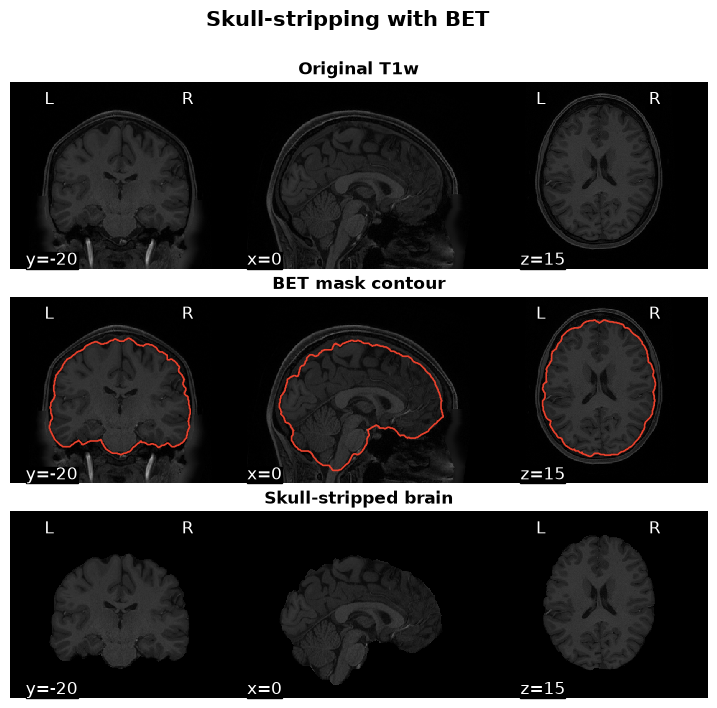

In [14]:
# Figure for 1.1a: original T1w, mask contour, skull-stripped brain
fig_dir = "figures"
mkdir_no_exist(fig_dir)

CUT = (0, -20, 15)

t1_brain = op.join(anat_out, "T1w_brain_R.nii.gz")
t1_mask  = op.join(anat_out, "T1w_brain_R_mask.nii.gz")

rows = ["Original T1w", "BET mask contour", "Skull-stripped brain"]

fig, axes = plt.subplots(3, 1, figsize=(9, 8))
fig.subplots_adjust(hspace=0.15)

plotting.plot_anat(t1_path, axes=axes[0], cut_coords=CUT, draw_cross=False, black_bg=True)

disp = plotting.plot_anat(t1_path, axes=axes[1], cut_coords=CUT, draw_cross=False, black_bg=True)
disp.add_contours(t1_mask, levels=[0.5], colors="#E8412C", linewidths=1.2)

plotting.plot_anat(t1_brain, axes=axes[2], cut_coords=CUT, draw_cross=False, black_bg=True)

# Centered title above each row
for ax, label in zip(axes, rows):
    ax.text(0.5, 1.02, label, transform=ax.transAxes,
            ha="center", va="bottom", fontsize=12, fontweight="bold")

fig.suptitle("Skull-stripping with BET", fontsize=15, fontweight="bold", y=0.97)

fig.savefig(op.join(fig_dir, "1a_skull_stripping.png"), dpi=300, bbox_inches="tight")
plt.show()

### 1.b. Tissue segmentation

The skull-stripped brain (`T1w_brain_R`, selected in 1.a) is segmented with FSL FAST into three tissue classes, which allows tissue-specific analyses (e.g. restricting to grey matter, or extracting white-matter/CSF signals).

- `-n 3`: three classes; FAST outputs a label map (`_seg`, 1 = CSF, 2 = grey matter, 3 = white matter) and one partial-volume map per class (`_pve_0/1/2`).
- Default settings are used (T1-weighted input, bias-field correction included).

The result is checked in FSLeyes and shown below on the same slices as the other figures (x = 0, y = −20, z = 15).

In [15]:
# Tissue segmentation with FAST (on the skull-stripped brain)
t1_brain = op.join(anat_out, "T1w_brain_R.nii.gz")   
segmentation_path = op.join(anat_out, "T1w_fast")                 

subprocess.run(["fast", "-n", "3", "-o", segmentation_path, t1_brain], check=True)

CompletedProcess(args=['fast', '-n', '3', '-o', 'derivatives/anat/T1w_fast', 'derivatives/anat/T1w_brain_R.nii.gz'], returncode=0)

In [16]:
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(t1_brain)
fsleyesDisplay.load(segmentation_path + "_seg.nii.gz")

**Check.** The segmentation follows the cortical folding; deep grey matter (thalamus, basal ganglia) is partly labelled as white matter (see report, Section 1.1b).

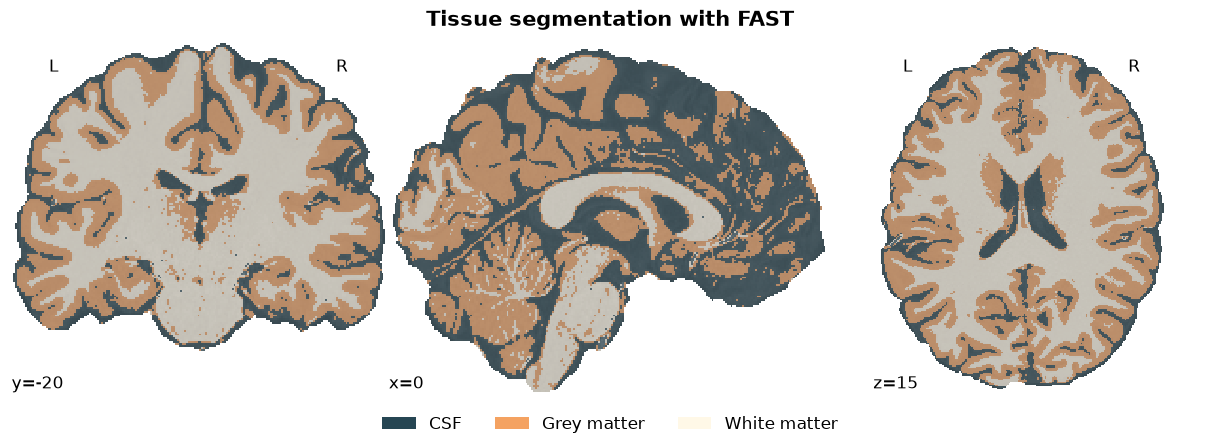

In [17]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

seg_path = segmentation_path + "_seg.nii.gz"

CUT = (0, -20, 15)

# One colour per tissue class (label 1 = CSF, 2 = GM, 3 = WM)
tissues = ["CSF", "Grey matter", "White matter"]
colors = ["#264653", "#F4A261", "#FFF8E7"]
cmap = ListedColormap(colors)

fig = plt.figure(figsize=(12, 4.5))
ax = fig.add_axes([0, 0.12, 1, 0.78])     # leave room for the title and the legend

plotting.plot_roi(seg_path, bg_img=t1_brain, cmap=cmap, vmin=1, vmax=3,
                  alpha=0.55, cut_coords=(0, -20, 15), draw_cross=False,
                  black_bg=False, axes=ax, figure=fig)

fig.suptitle("Tissue segmentation with FAST", fontsize=15, fontweight="bold", y=0.97)
fig.legend(handles=[Patch(facecolor=c, label=t) for c, t in zip(colors, tissues)],
           loc="lower center", ncol=3, frameon=False, fontsize=12)

fig.savefig(op.join(fig_dir, "1b_segmentation.png"), dpi=300, bbox_inches="tight")
plt.show()

### 1.c. Registration

The skull-stripped T1w is registered to the MNI152 1 mm brain template, so that the subject's anatomy can be compared with atlases and with the functional data, which are already in MNI space.

We first use FSL FLIRT (affine, 12 degrees of freedom, the default) and compare three cost functions:
- `leastsq`: least squares, assumes identical intensities in both images;
- `normcorr`: normalised correlation, assumes a linear intensity relationship;
- `corratio`: correlation ratio, allows any functional intensity relationship (FLIRT default).

Each run saves the registered image and its transformation matrix (`.mat`).

In [18]:
# Linear (affine) registration of the T1 to MNI space with FLIRT
source    = op.join(anat_out, "T1w_brain_R.nii.gz")   
reference = op.expandvars(op.join("$FSLDIR", "data", "standard", "MNI152_T1_1mm_brain.nii.gz"))  
result    = op.join(anat_out, "T1w_mni")

costs_to_consider = ["leastsq", "normcorr", "corratio"]

for c in costs_to_consider:
    subprocess.run(["flirt", "-in", source, "-ref", reference,
                    "-out", result + "_" + c,
                    "-omat", result + "_" + c + ".mat",
                    "-cost", c], check=True)

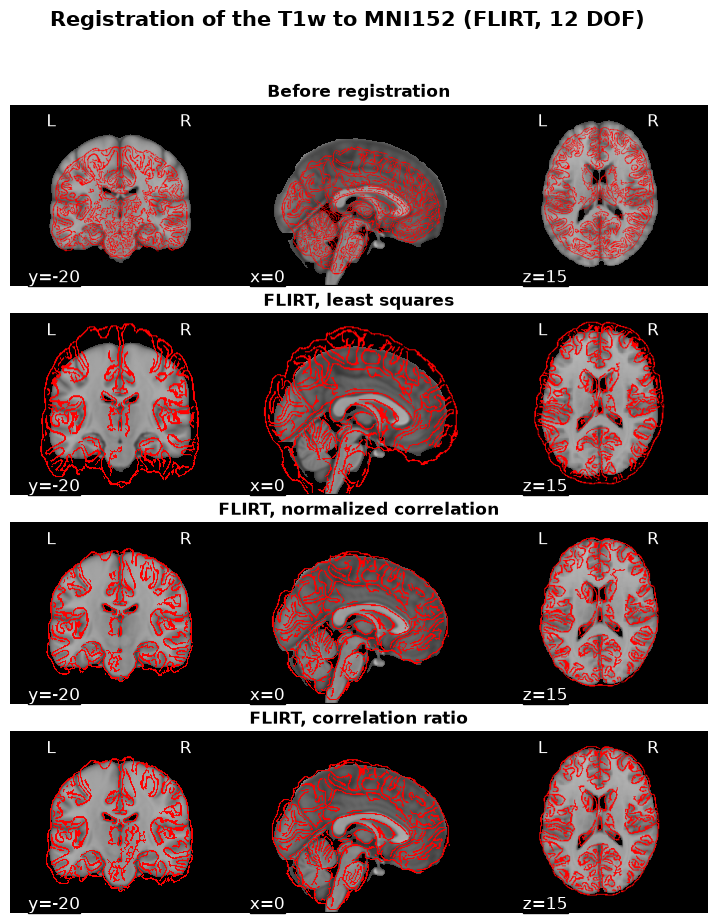

In [19]:
# Plot 1.c): Difference between linear registrations (not in report)
labels = ["Before registration", "FLIRT, least squares",
          "FLIRT, normalized correlation", "FLIRT, correlation ratio"]
images = [source] + [result + "_" + c + ".nii.gz" for c in ["leastsq", "normcorr", "corratio"]]

fig, axes = plt.subplots(4, 1, figsize=(9, 10.5))
fig.subplots_adjust(hspace=0.15)

for ax, img, label in zip(axes, images, labels):
    disp = plotting.plot_anat(reference, axes=ax, cut_coords=CUT,
                              draw_cross=False, black_bg=True)
    disp.add_edges(img, color="r")
    ax.text(0.5, 1.02, label, transform=ax.transAxes,
            ha="center", va="bottom", fontsize=12, fontweight="bold")

fig.suptitle("Registration of the T1w to MNI152 (FLIRT, 12 DOF)",
             fontsize=15, fontweight="bold", y=0.97)
fig.savefig(op.join(fig_dir, "1c_registration_costs.png"), dpi=300, bbox_inches="tight")
plt.show()

In [20]:
# Pearson correlation between registered T1 and MNI template intensities
ref_data = nib.load(reference).get_fdata()
brain = ref_data > 0
for c in costs_to_consider:
    reg = nib.load(result + "_" + c + ".nii.gz").get_fdata()
    r = np.corrcoef(reg[brain], ref_data[brain])[0, 1]
    print(f"{c:10s} correlation with MNI: {r:.3f}")

leastsq    correlation with MNI: 0.483
normcorr   correlation with MNI: 0.625
corratio   correlation with MNI: 0.622


**Comparison:** The edges of the registered T1w (red) are overlaid on the MNI template. `normcorr` and `corratio` give a similar, clearly better alignment than `leastsq` (correlation with the template: 0.63, 0.62 and 0.48). As an affine transform cannot absorb local anatomical differences between the subject and the template, a non-linear registration is computed next.

As an affine transform cannot account for local anatomical differences between the subject and the template, we add a non-linear registration with ANTs SyN (`antsRegistrationSyN.sh -t s`: rigid, then affine, then symmetric diffeomorphic SyN). The output prefix `T1w_to_mni_synfull_` gives the registered image (`Warped`), the affine matrix (`0GenericAffine.mat`) and the non-linear deformation field (`1Warp`).

In [21]:
# Non-linear registration of the T1 to MNI space with ANTs SyN (rigid + affine + SyN)
syn_full_prefix = op.join(anat_out, "T1w_to_mni_synfull_")
subprocess.run(["antsRegistrationSyN.sh", "-d", "3", "-f", reference,
                "-m", op.join(anat_out, "T1w_brain_R.nii.gz"),
                "-t", "s", "-n", "4", "-o", syn_full_prefix], check=True)


--------------------------------------------------------------------------------------
 Mapping parameters
--------------------------------------------------------------------------------------
 Dimensionality:           3
 Output name prefix:       derivatives/anat/T1w_to_mni_synfull_
 Fixed images:             /cvmfs/neurodesk.ardc.edu.au/containers/fsl_6.0.7.18_20250928/fsl_6.0.7.18_20250928.simg/opt/fsl-6.0.7.18//data/standard/MNI152_T1_1mm_brain.nii.gz
 Moving images:            derivatives/anat/T1w_brain_R.nii.gz
 Mask images:              
 Initial transforms:       
 Number of threads:        4
 Spline distance:          26
 Linear gradient step:     0.1
 SyN gradient step:        0.2
 Transform type:           s
 CC radius:                2
 Precision:                d
 Use histogram matching    0
 Repro                     0
 antsRegistration call:
--------------------------------------------------------------------------------------
antsRegistration --verbose 1 --dimensiona

CompletedProcess(args=['antsRegistrationSyN.sh', '-d', '3', '-f', '/cvmfs/neurodesk.ardc.edu.au/containers/fsl_6.0.7.18_20250928/fsl_6.0.7.18_20250928.simg/opt/fsl-6.0.7.18//data/standard/MNI152_T1_1mm_brain.nii.gz', '-m', 'derivatives/anat/T1w_brain_R.nii.gz', '-t', 's', '-n', '4', '-o', 'derivatives/anat/T1w_to_mni_synfull_'], returncode=0)

In [22]:
# non-linear (affine) registration of the T1 to MNI space with ANTS
ref_data = nib.load(reference).get_fdata()
brain = ref_data > 0

for name in ["T1w_mni_normcorr", "T1w_to_mni_synfull_Warped"]:
    reg_data = nib.load(op.join(anat_out, name + ".nii.gz")).get_fdata()
    r = np.corrcoef(reg_data[brain], ref_data[brain])[0, 1]
    print(f"{name:28s} correlation with MNI: {r:.3f}")

T1w_mni_normcorr             correlation with MNI: 0.625
T1w_to_mni_synfull_Warped    correlation with MNI: 0.861


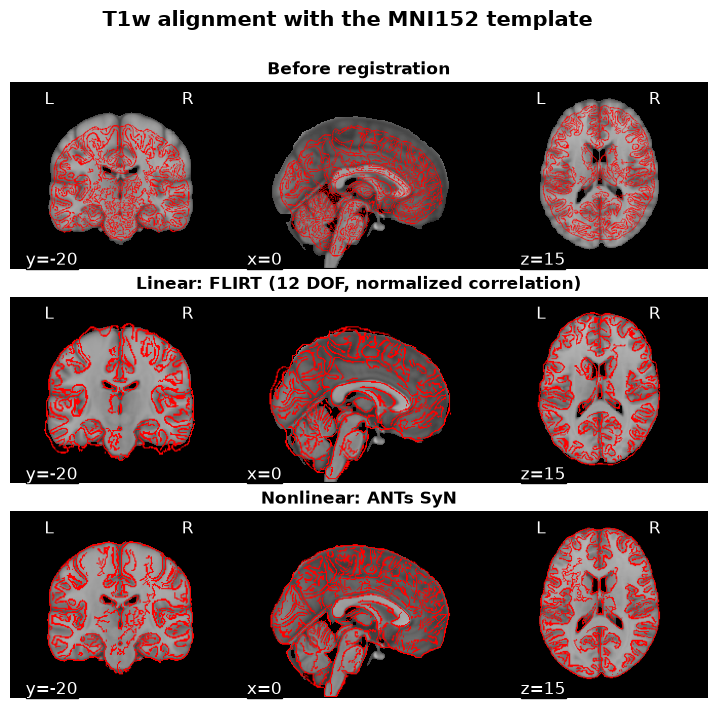

In [23]:
# Plot 1.c): Comparison of linear (FLIRT) and non-linear (ANTs SyN) registration
labels = ["Before registration",
          "Linear: FLIRT (12 DOF, normalized correlation)",
          "Nonlinear: ANTs SyN"]
images = [source,
          op.join(anat_out, "T1w_mni_normcorr.nii.gz"),
          op.join(anat_out, "T1w_to_mni_synfull_Warped.nii.gz")]

fig, axes = plt.subplots(3, 1, figsize=(9, 8))
fig.subplots_adjust(hspace=0.15)

for ax, img, label in zip(axes, images, labels):
    disp = plotting.plot_anat(reference, axes=ax, cut_coords=CUT,
                              draw_cross=False, black_bg=True)
    disp.add_edges(img, color="r")
    ax.text(0.5, 1.02, label, transform=ax.transAxes,
            ha="center", va="bottom", fontsize=12, fontweight="bold")

fig.suptitle("T1w alignment with the MNI152 template", fontsize=15, fontweight="bold", y=0.97)
fig.savefig(op.join(fig_dir, "1c_registration.png"), dpi=300, bbox_inches="tight")
plt.show()

**Comparison:** The correlation with the MNI template rises from 0.63 (FLIRT, normalised correlation) to 0.86 (ANTs SyN), and the edges of the SyN-registered T1w match the template more closely, especially around the ventricles and the cortical boundary. SyN is therefore used as the final registration.

To check that the non-linear warp is physically plausible, we compute the Jacobian determinant of the deformation field, i.e. the local volume change: > 1 expansion, < 1 compression, ≤ 0 folding (non-invertible, implausible).

In [24]:
# Jacobian determinant of the non-linear warp affine (local volume change: >1 expansion, <1 compression, <=0 folding)
jac_path = op.join(anat_out, "T1w_to_mni_synfull_jacobian.nii.gz")
subprocess.run(["CreateJacobianDeterminantImage", "3",
                syn_full_prefix + "1Warp.nii.gz", jac_path, "0", "0"], check=True)

jac = nib.load(jac_path).get_fdata()[brain]
print(f"Jacobian: min = {jac.min():.2f}, max = {jac.max():.2f}, "
      f"1st-99th percentile = [{np.percentile(jac, 1):.2f}, {np.percentile(jac, 99):.2f}]")

Jacobian: min = 0.09, max = 7.28, 1st-99th percentile = [0.35, 2.30]


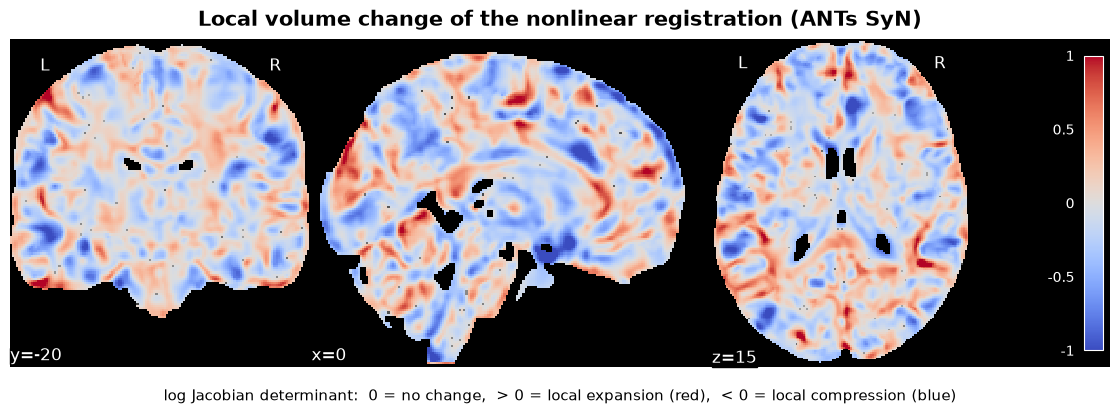

In [25]:
# Visual check of the deformation (not in the report): log-Jacobian, 0 = no volume change
jac_img  = nib.load(jac_path)
mni_mask = nib.load(reference).get_fdata() > 0

# Only brain displayed
log_jac = np.log(jac_img.get_fdata().clip(1e-3)) * mni_mask
log_jac_img = nib.Nifti1Image(log_jac, jac_img.affine)

fig = plt.figure(figsize=(11, 4.2))
ax = fig.add_axes([0, 0.12, 1, 0.78])

plotting.plot_stat_map(log_jac_img, bg_img=reference, cut_coords=CUT, axes=ax,
                       cmap="coolwarm", vmax=1, symmetric_cbar=True,
                       threshold=1e-3, draw_cross=False, black_bg=True,
                       annotate=True, colorbar=True)

fig.suptitle("Local volume change of the nonlinear registration (ANTs SyN)",
             fontsize=15, fontweight="bold", y=0.97)
fig.text(0.5, 0.04, "log Jacobian determinant:  0 = no change,  > 0 = local expansion (red),"
         "  < 0 = local compression (blue)", ha="center", fontsize=11)

fig.savefig(op.join(fig_dir, "appendix_jacobian.png"), dpi=300, bbox_inches="tight")
plt.show()

**Check:** The Jacobian stays positive in the whole brain (min 0.09, 1st–99th percentile 0.35–2.31), so the warp contains no folding. Local expansions and compressions are spread over the cortex, as expected when adapting individual folding to the template.

The same SyN transform (non-linear warp followed by the affine) is applied to the FAST segmentation, so that tissue labels are available in MNI space. `GenericLabel` interpolation keeps integer labels (1 = CSF, 2 = GM, 3 = WM) instead of averaging them.

In [26]:
# RUN: Apply the full SyN transform (affine + nonlinear warp) to the FAST segmentation
seg_mni = op.join(anat_out, "T1w_fast_seg_mni.nii.gz")

subprocess.run(["antsApplyTransforms", "-d", "3",
                "-i", segmentation_path + "_seg.nii.gz",       # FAST labels (1=CSF, 2=GM, 3=WM)
                "-r", reference,                                # MNI152 1 mm grid
                "-t", syn_full_prefix + "1Warp.nii.gz",         # nonlinear warp
                "-t", syn_full_prefix + "0GenericAffine.mat",   # affine
                "-n", "GenericLabel",                           # keeps integer labels
                "-o", seg_mni], check=True)


CompletedProcess(args=['antsApplyTransforms', '-d', '3', '-i', 'derivatives/anat/T1w_fast_seg.nii.gz', '-r', '/cvmfs/neurodesk.ardc.edu.au/containers/fsl_6.0.7.18_20250928/fsl_6.0.7.18_20250928.simg/opt/fsl-6.0.7.18//data/standard/MNI152_T1_1mm_brain.nii.gz', '-t', 'derivatives/anat/T1w_to_mni_synfull_1Warp.nii.gz', '-t', 'derivatives/anat/T1w_to_mni_synfull_0GenericAffine.mat', '-n', 'GenericLabel', '-o', 'derivatives/anat/T1w_fast_seg_mni.nii.gz'], returncode=0)

## 2. Functional preprocessing

Motion correction, framewise displacement, Gaussian smoothing, and anatomical–functional alignment QC. The outputs are saved in `derivatives/func/` and `figures/`.

In [27]:
os.makedirs(func_out, exist_ok=True)
fig_dir = "figures"
os.makedirs(fig_dir, exist_ok=True)

fmri_img = nib.load(fmri_path)
n_volumes = fmri_img.shape[3]

TR = float(fmri_img.header.get_zooms()[3])  # TR = 0.72 s (see data inspection)

frame_times = np.arange(n_volumes) * TR

# middle volume: MCFLIRT reference and QC figures
volume_index = n_volumes // 2

CUT_FUNC = (0, -20, 15)       # same coordinated as in 1.1

func_prefix = op.join(func_out, "tfMRI_LANGUAGE_LR")

print(f"Volumes: {n_volumes}; TR: {TR:.3f} s; duration: {n_volumes * TR:.1f} s")
print(f"Volumes: {n_volumes}; TR: {TR:.2f} s; duration: {n_volumes * TR:.1f} s; " f"reference volume: {volume_index}")

Volumes: 316; TR: 0.720 s; duration: 227.5 s
Volumes: 316; TR: 0.72 s; duration: 227.5 s; reference volume: 158


### 2.a. Motion correction and framewise displacement

MCFLIRT aligns each volume to the middle volume using six rigid-body parameters. Power FD combines successive translations with rotations converted to displacement using a 50 mm radius. The first frame has no defined FD.

Motion outliers are screened using Q3 + 1.5 × IQR, following Lab 3. Candidate spike regressors are saved for subsequent GLM review.

Reference: [FSL MCFLIRT](https://fsl.fmrib.ox.ac.uk/fsl/docs/registration/mcflirt.html).

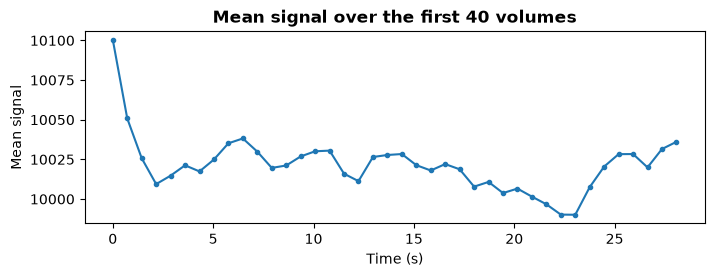

In [28]:
# mean in-brain signal over the first volumes, to check for non-steady-state volumes
data = nib.load(fmri_path).get_fdata()
mean_signal = data[data[..., 0] > 0].mean(axis=0)      # mean over in-brain voxels, per volume

plt.figure(figsize=(8, 2.5))
plt.plot(frame_times[:40], mean_signal[:40], marker="o", ms=3)
plt.xlabel("Time (s)")
plt.ylabel("Mean signal")
plt.title("Mean signal over the first 40 volumes", fontweight="bold")

plt.show()

We can see that there are small initial transient visible (first 3 volumes, ~1% above), but given its short duration (~2 s) relative to the ~30 s task blocks, it is probably negligible for the story-math contrast; these volumes are therefore kept.

In [29]:
# RUN: rigid-body realignment, keeping the original temporal grid
moco_prefix = func_prefix + "_moco"
moco_path = moco_prefix + ".nii.gz"
subprocess.run(["mcflirt", "-in", fmri_path, "-out", moco_prefix,
                "-dof", "6", "-refvol", str(volume_index),
                "-plots", "-mats", "-report"], check=True)

corrected = nib.load(moco_path)
print("Motion-corrected image:", moco_path)

Processed data will be saved as derivatives/func/tfMRI_LANGUAGE_LR_moco

McFLIRT v 2.0 - FMRI motion correction

Reading time series... 
first iteration - 8mm scaling, set tolerance
Rescaling reference volume [158] to 8 mm pixels
Registering volumes ... [159][160][161][162][163][164][165][166][167][168][169][170][171][172][173][174][175][176][177][178][179][180][181][182][183][184][185][186][187][188][189][190][191][192][193][194][195][196][197][198][199][200][201][202][203][204][205][206][207][208][209][210][211][212][213][214][215][216][217][218][219][220][221][222][223][224][225][226][227][228][229][230][231][232][233][234][235][236][237][238][239][240][241][242][243][244][245][246][247][248][249][250][251][252][253][254][255][256][257][258][259][260][261][262][263][264][265][266][267][268][269][270][271][272][273][274][275][276][277][278][279][280][281][282][283][284][285][286][287][288][289][290][291][292][293][294][295][296][297][298][299][300][301][302][303][304][305][306][307][

refnum = 158
Original_refvol = 158



Saving motion corrected time series... 


Motion-corrected image: derivatives/func/tfMRI_LANGUAGE_LR_moco.nii.gz


In [30]:
# Power FD: sum of absolute successive translations and rotations (radius = 50 mm)
def compute_fd_power(parameters, radius_mm=50.0):
    parameters = np.asarray(parameters, dtype=float)
    delta = np.diff(parameters, axis=0)
    differences = (np.abs(delta[:, 3:]).sum(axis=1)
                   + radius_mm * np.abs(delta[:, :3]).sum(axis=1))
    return np.r_[np.nan, differences]

motion = np.loadtxt(moco_prefix + ".par", ndmin=2)
fd = compute_fd_power(motion)

# Exploratory Tukey outlier threshold.
q25, q75 = np.quantile(fd[1:], [0.25, 0.75])
fd_threshold = q75 + 1.5 * (q75 - q25)
bad_motion = np.isfinite(fd) & (fd > fd_threshold)
bad_indices = np.flatnonzero(bad_motion)

motion_columns = ["rot_x", "rot_y", "rot_z", "trans_x", "trans_y", "trans_z"]
qc = pd.DataFrame(motion, columns=motion_columns)
qc.insert(0, "volume", np.arange(n_volumes))
qc.insert(1, "time_s", frame_times)
qc["framewise_displacement_mm"] = fd
qc["motion_outlier"] = bad_motion.astype(int)
qc.to_csv(func_prefix + "_motion_qc.tsv", sep="\t", index=False, na_rep="n/a")

# Candidate motion and spike regressors
motion_confounds = pd.DataFrame(motion, columns=motion_columns)
for idx in bad_indices:
    motion_confounds[f"motion_outlier_{idx:03d}"] = (np.arange(n_volumes) == idx).astype(int)
motion_confounds.to_csv(func_prefix + "_motion_confounds.tsv", sep="\t", index=False)
print(f"FD mean: {np.mean(fd[1:]):.4f} mm; max: {np.max(fd[1:]):.4f} mm")
print(f"Exploratory FD threshold: {fd_threshold:.4f} mm")
print(f"Flagged transitions: {len(bad_indices)}/{n_volumes - 1}")
print("Flagged volume indices (zero-based):", bad_indices.tolist())

FD mean: 0.0848 mm; max: 0.2592 mm
Exploratory FD threshold: 0.2334 mm
Flagged transitions: 3/315
Flagged volume indices (zero-based): [25, 26, 45]


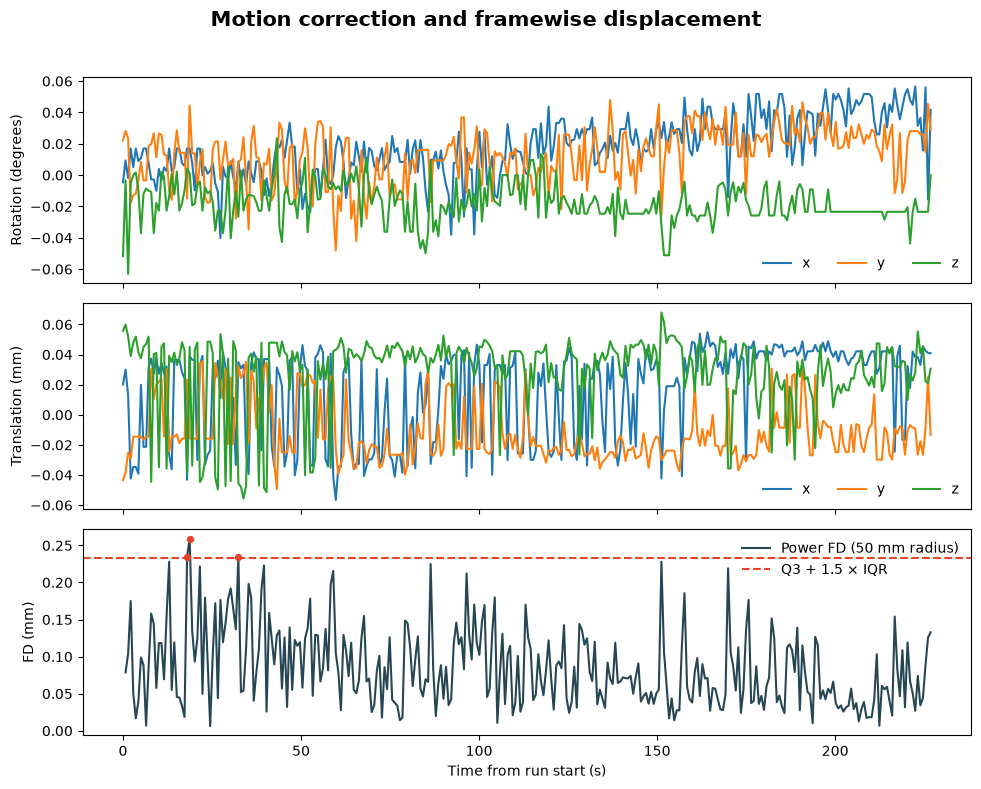

In [31]:
# Report figure: motion parameters and framewise displacement
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for j, axis in enumerate("xyz"):
    axes[0].plot(frame_times, np.rad2deg(motion[:, j]), label=axis)
    axes[1].plot(frame_times, motion[:, j + 3], label=axis)
axes[0].set_ylabel("Rotation (degrees)")
axes[1].set_ylabel("Translation (mm)")
for ax in axes[:2]:
    ax.legend(ncol=3, frameon=False)
axes[2].plot(frame_times, fd, color="#264653", label="Power FD (50 mm radius)")
axes[2].axhline(fd_threshold, color="#E8412C", ls="--", label="Q3 + 1.5 × IQR")
axes[2].scatter(frame_times[bad_motion], fd[bad_motion], color="#E8412C", s=18, zorder=3)
axes[2].set_ylabel("FD (mm)")
axes[2].set_xlabel("Time from run start (s)")
axes[2].legend(frameon=False)
fig.suptitle("Motion correction and framewise displacement", fontsize=15, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.savefig(op.join(fig_dir, "2a_motion_fd.png"), dpi=300, bbox_inches="tight")
plt.show()

#### Motion QC

Mean/max FD, flagged-frame count, and temporal distribution are reported below after execution.

### 2.b. Gaussian smoothing

A 6 mm FWHM Gaussian kernel is applied to the motion-corrected series, following Lab 3. Spatial averaging trades fine detail for sensitivity to extended effects. FSL uses sigma in mm: $\sigma = \mathrm{FWHM}/\sqrt{8\ln 2} \approx 2.55$ mm.

The unsmoothed series is retained. No temporal filtering is applied at this stage.

FWHM = 6 mm; sigma = 2.548 mm


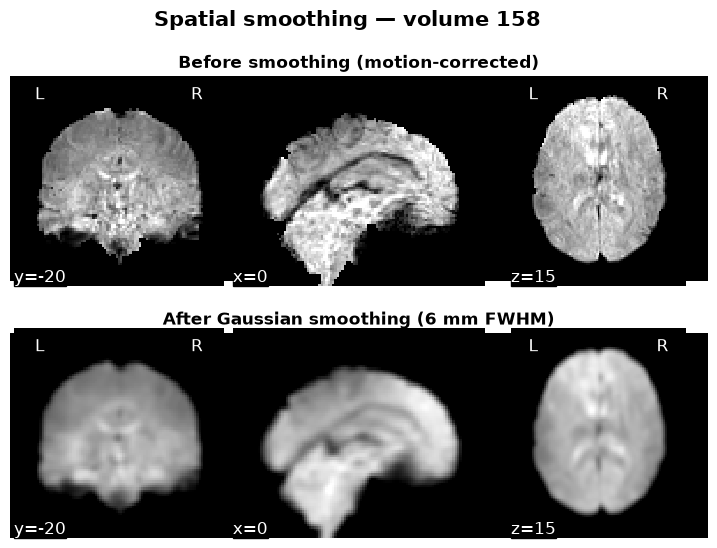

In [32]:
# RUN: Gaussian spatial smoothing, as in Lab 3
FWHM_MM = 6.0
sigma_mm = FWHM_MM / np.sqrt(8 * np.log(2))
smoothed_path = func_prefix + "_moco_smoothed-6mm.nii.gz"
subprocess.run(["fslmaths", moco_path, "-s", str(sigma_mm), smoothed_path], check=True)
smoothed = nib.load(smoothed_path)
print(f"FWHM = {FWHM_MM:g} mm; sigma = {sigma_mm:.3f} mm")

# Extract the same volume before and after smoothing.
volume_before = nib.Nifti1Image(np.asarray(corrected.dataobj[..., volume_index], dtype=np.float32),
                               corrected.affine)
volume_after = nib.Nifti1Image(np.asarray(smoothed.dataobj[..., volume_index], dtype=np.float32),
                              smoothed.affine)
nonzero = volume_before.get_fdata()
nonzero = nonzero[np.isfinite(nonzero) & (nonzero > 0)]

vmin, vmax = np.percentile(nonzero, [2, 98])
fig, axes = plt.subplots(2, 1, figsize=(9, 6))
for ax, image, label in zip(axes, [volume_before, volume_after],
                           ["Before smoothing (motion-corrected)", "After Gaussian smoothing (6 mm FWHM)"]):
    plotting.plot_anat(image, axes=ax, cut_coords=CUT_FUNC, draw_cross=False,
                       black_bg=True, vmin=vmin, vmax=vmax)
    ax.text(0.5, 1.02, label, transform=ax.transAxes,
            ha="center", va="bottom", fontsize=12, fontweight="bold")
fig.suptitle(f"Spatial smoothing — volume {volume_index}", fontsize=15, fontweight="bold", y=0.99)
fig.subplots_adjust(hspace=0.25)
fig.savefig(op.join(fig_dir, "2b_smoothing.png"), dpi=300, bbox_inches="tight")
plt.show()

#### Smoothing QC

The same volume is displayed before and after smoothing using identical coordinates and intensity limits. Spatial averaging reduces sharpness and mixes signal across tissue boundaries.

### 2.c. Anatomical–functional alignment

One unsmoothed, motion-corrected volume is overlaid on the selected MNI T1. Multiple axial levels are displayed; other orientations can be inspected in FSLeyes.

As shown in the data inspection (Part 1.1), the functional data are already in MNI152 space (91 × 109 × 91 grid, 2 mm). No functional-to-MNI registration was therefore performed. Alignment with the MNI-registered T1 was checked visually.

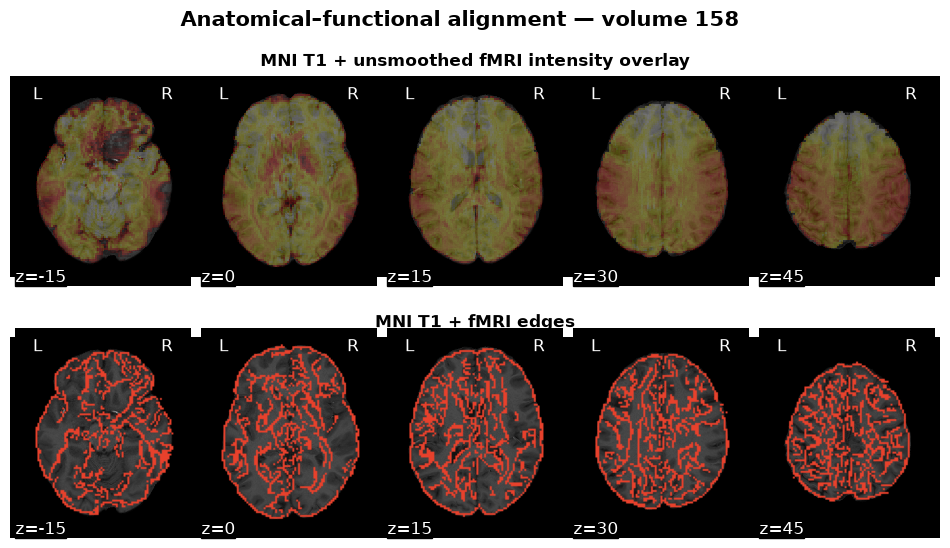

In [33]:
# Explicit choice: the selected anatomical result from Section 1
anat_mni_path = op.join(anat_out, "T1w_to_mni_synfull_Warped.nii.gz")
qc_volume_path = func_prefix + f"_moco_vol-{volume_index:03d}.nii.gz"
nib.save(volume_before, qc_volume_path)

# Display in world coordinates; no registration is estimated here.
z_cuts = [-15, 0, 15, 30, 45]
fig, axes = plt.subplots(2, 1, figsize=(12, 6))
disp = plotting.plot_anat(anat_mni_path, axes=axes[0], display_mode="z", cut_coords=z_cuts,
                          draw_cross=False, black_bg=True)
disp.add_overlay(volume_before, cmap="hot", threshold=float(vmin), alpha=0.25,
                 vmin=float(vmin), vmax=float(vmax), colorbar=False)
axes[0].text(0.5, 1.03, "MNI T1 + unsmoothed fMRI intensity overlay", transform=axes[0].transAxes,
             ha="center", va="bottom", fontsize=12, fontweight="bold")
disp = plotting.plot_anat(anat_mni_path, axes=axes[1], display_mode="z", cut_coords=z_cuts,
                          draw_cross=False, black_bg=True)
disp.add_edges(volume_before, color="#E8412C")
axes[1].text(0.5, 1.03, "MNI T1 + fMRI edges", transform=axes[1].transAxes,
             ha="center", va="bottom", fontsize=12, fontweight="bold")
fig.suptitle(f"Anatomical–functional alignment — volume {volume_index}",
             fontsize=15, fontweight="bold", y=0.99)
fig.subplots_adjust(hspace=0.3)
fig.savefig(op.join(fig_dir, "2c_anat_func_alignment.png"), dpi=300, bbox_inches="tight")
plt.show()

In [34]:
# FSLeyes inspection
# fsleyesDisplay.resetOverlays()
# fsleyesDisplay.load(anat_mni_path)
# fsleyesDisplay.load(qc_volume_path)

#### Alignment QC

The fMRI volume is well aligned with the MNI-registered T1: the outer brain boundary and the lateral ventricles coincide across slices. Small mismatches at the edges are expected, since the HCP functional data and our T1 were normalised to MNI with different pipelines (FNIRT vs. ANTs SyN). A signal void is visible in right ventral anterior regions (z = −15) while the brain outline remains aligned. This could be due to susceptibility-induced signal dropout rather than misregistration.

In [35]:
# Inputs for the GLM (Part 1.3)
fmri_preproc_path = smoothed_path
confounds_path = func_prefix + "_motion_confounds.tsv"
print("GLM input:", fmri_preproc_path)
print("GLM confounds:", confounds_path)

GLM input: derivatives/func/tfMRI_LANGUAGE_LR_moco_smoothed-6mm.nii.gz
GLM confounds: derivatives/func/tfMRI_LANGUAGE_LR_motion_confounds.tsv


In [36]:
# Some data for analysis

print(f"\nMean FD: {np.mean(fd[1:]):.4f} mm")
print(f"Maximum FD: {np.max(fd[1:]):.4f} mm")
print(f"FD threshold: {fd_threshold:.4f} mm")
print(f"Number of flagged volumes: {len(bad_indices)}")
print("Flagged volumes (zero-based):", bad_indices.tolist())


Mean FD: 0.0848 mm
Maximum FD: 0.2592 mm
FD threshold: 0.2334 mm
Number of flagged volumes: 3
Flagged volumes (zero-based): [25, 26, 45]


## 3. GLM

### 3.a. Experimental design matrix

In [37]:
# Task events
events_all = pd.read_csv(onset_path)
print(events_all.columns.tolist())
print(events_all["trial_type"].value_counts())
events_all.head(15)

['onset', 'duration', 'trial_type']
trial_type
present_math      9
math              9
question_math     9
response_math     9
cue               7
story             4
present_story     4
question_story    4
response_story    4
Name: count, dtype: int64


,onset,duration,trial_type
0,0.241,28.270,story
1,0.241,20.445,present_story
2,21.192,1.161,question_story
3,25.550,2.961,response_story
4,28.696,0.727,cue
5,30.095,5.667,present_math
6,30.095,12.241,math
7,35.946,3.391,question_math
8,39.371,2.965,response_math
9,42.570,5.453,present_math


The onset file contains the block-level conditions (`story`, `math`), their sub-phases (`present_*`, `question_*`, `response_*`) and the `cue` preceding each block. As the sub-phases are nested within the blocks, only the block-level conditions are modelled, to avoid redundant regressors.

In [38]:
# Keep the block-level conditions only
events = events_all[events_all["trial_type"].isin(["story", "math"])][["onset", "duration", "trial_type"]]
print(events["trial_type"].value_counts())

trial_type
math     9
story    4
Name: count, dtype: int64


In [39]:
confounds = pd.read_csv(confounds_path, sep="\t") 

First-level GLM (one subject, one run) fitted with nilearn on the smoothed fMRI (no additional smoothing):
- task regressors: story and math blocks convolved with the canonical SPM HRF;
- nuisance regressors: six motion parameters and three spike regressors from Part 1.2
- slow drifts: cosine basis, 125 s high-pass cut-off
- AR(1) noise model for the temporal autocorrelation

In [40]:
# Model specification and fit
# Cosine drift model, high-pass 0.008 Hz (125 s cut-off): removes slow scanner drifts;
# 125 s rather than 100 s because the 100 s basis produced a drift term correlated with the task (see 3b)
fmri_glm = FirstLevelModel(t_r=TR, noise_model="ar1", standardize=False,
                           hrf_model="spm", drift_model="cosine", high_pass=0.008,
                           smoothing_fwhm=None)
fmri_glm = fmri_glm.fit(fmri_preproc_path, events=events, confounds=confounds)

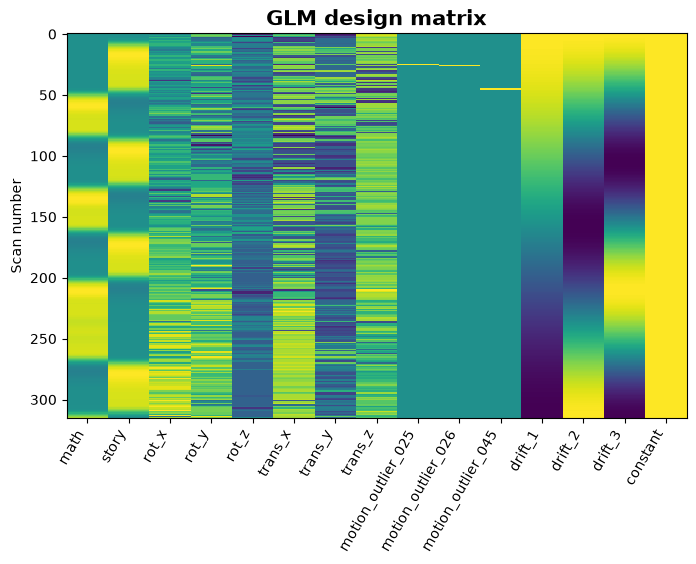

In [41]:
design_matrix = fmri_glm.design_matrices_[0]
dm = design_matrix / np.abs(design_matrix).max(axis=0)  

fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(dm.values, aspect="auto", cmap="viridis", interpolation="nearest")
ax.set_xticks(range(dm.shape[1]))
ax.set_xticklabels(dm.columns, rotation=60, ha="right")
ax.set_ylabel("Scan number")
ax.set_title("GLM design matrix", fontsize=15, fontweight="bold")
fig.savefig(op.join(fig_dir, "3a_design_matrix.png"), dpi=300, bbox_inches="tight")
plt.show()

Shape: (316, 15)
Confounds identical: True


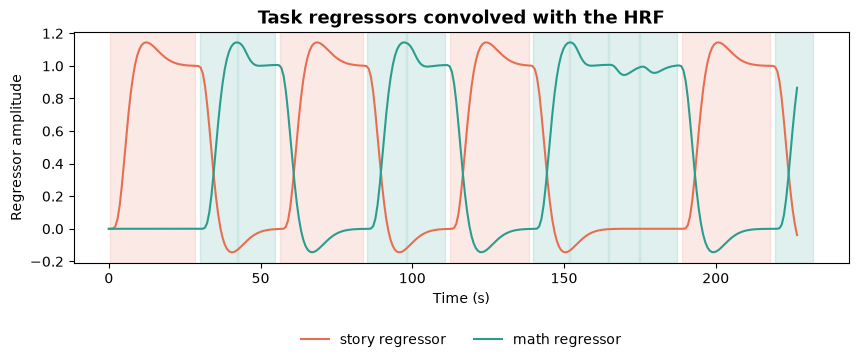

In [42]:
# Check of the design matrix: dimensions, confounds, and task regressors vs. block timing
# (each regressor should rise during its own blocks, delayed by the HRF)
dm = design_matrix
print("Shape:", dm.shape)
print("Confounds identical:", np.allclose(dm[confounds.columns].values, confounds.values))

fig, ax = plt.subplots(figsize=(10, 3))
for cond, color in [("story", "#E76F51"), ("math", "#2A9D8F")]:
    ax.plot(frame_times, dm[cond], color=color, label=f"{cond} regressor")
    for _, ev in events[events.trial_type == cond].iterrows():
        ax.axvspan(ev.onset, ev.onset + ev.duration, color=color, alpha=0.15)  # shaded block
ax.set_xlabel("Time (s)")
ax.set_ylabel("Regressor amplitude")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2, frameon=False)
ax.set_title("Task regressors convolved with the HRF", fontsize=13, fontweight="bold")
fig.savefig(op.join(fig_dir, "3a_task_regressors.png"), dpi=300, bbox_inches="tight")
plt.show()

**Check:** The design matrix has 316 rows (volumes) and 15 columns, and the confounds are included unchanged. Each task regressor rises during its own blocks, delayed by the HRF. Story and math alternate with almost no rest, so the implicit baseline is poorly sampled.

### 3.b. Correlation matrix

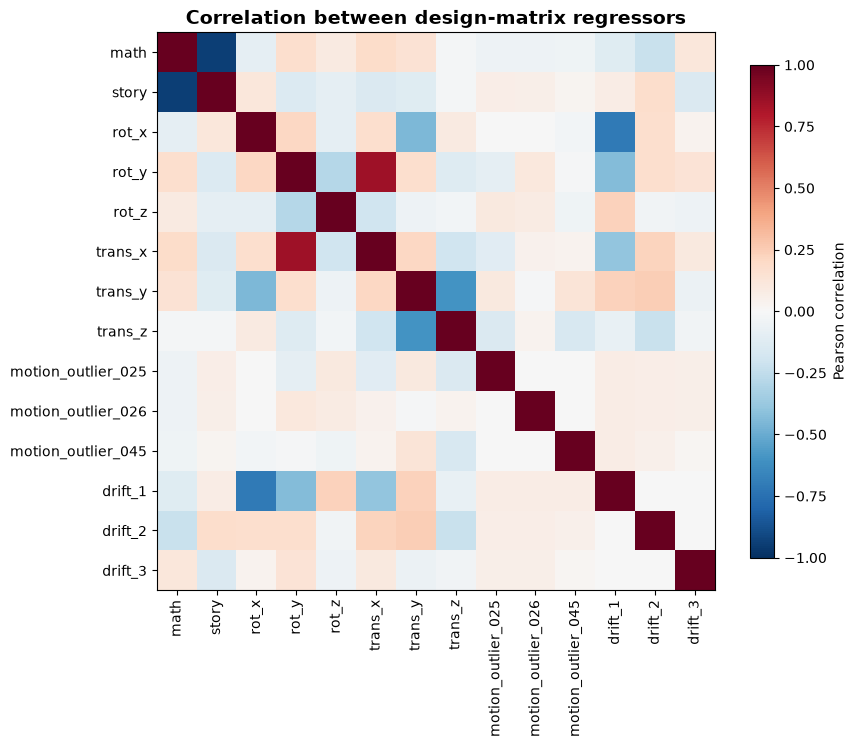

story vs math: r = -0.94
       rot_x  rot_y  rot_z  trans_x  trans_y  trans_z  motion_outlier_025  \
story   0.11  -0.14  -0.09    -0.14    -0.12    -0.02                0.06   
math   -0.09   0.17   0.09     0.18     0.14    -0.02               -0.05   

       motion_outlier_026  motion_outlier_045  drift_1  drift_2  drift_3  
story                0.06                0.03     0.08     0.17    -0.14  
math                -0.05               -0.05    -0.12    -0.22     0.11  


In [43]:
# Pearson correlation between the regressors of the design matrix
regressors = design_matrix.drop(columns="constant")
corr = regressors.corr()

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns)
fig.colorbar(im, ax=ax, label="Pearson correlation", shrink=0.8)
ax.set_title("Correlation between design-matrix regressors", fontsize=14, fontweight="bold")
fig.savefig(op.join(fig_dir, "3b_regressor_correlation.png"), dpi=300, bbox_inches="tight")
plt.show()

# Key values
print(f"story vs math: r = {corr.loc['story', 'math']:.2f}")
task_vs_nuisance = corr.loc[["story", "math"]].drop(columns=["story", "math"])
print(task_vs_nuisance.round(2))

**Result:** Story and math are strongly anticorrelated (r = −0.94), as they alternate without rest. Task regressors are only weakly correlated with motion (|r| ≤ 0.18), spike regressors (|r| ≤ 0.06) and drifts (|r| ≤ 0.22), so the task effects can be estimated independently of the nuisance regressors.

### 3.c. Statistical maps

Each task regressor is tested against the implicit baseline (periods not covered by any task regressor). Maps are thresholded with FDR (q < 0.05, two-sided) and a minimum cluster size of 10 voxels.

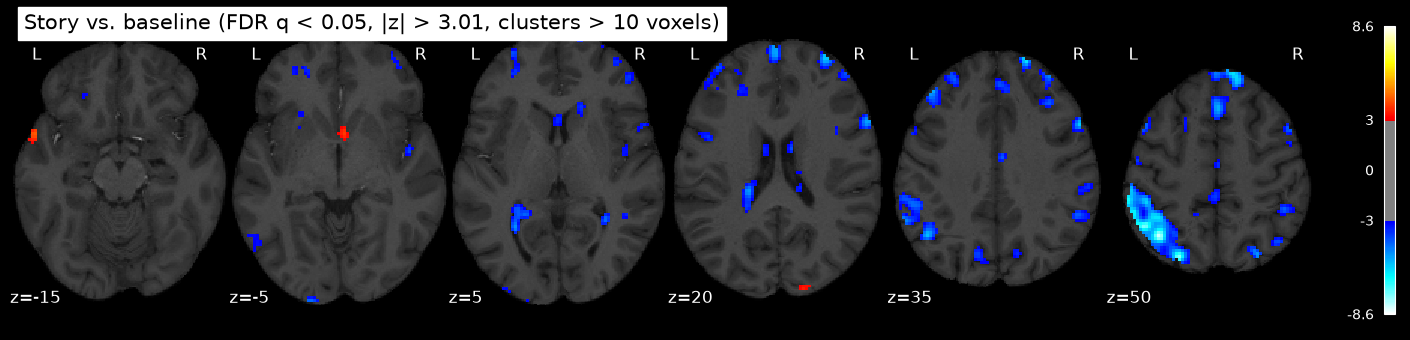

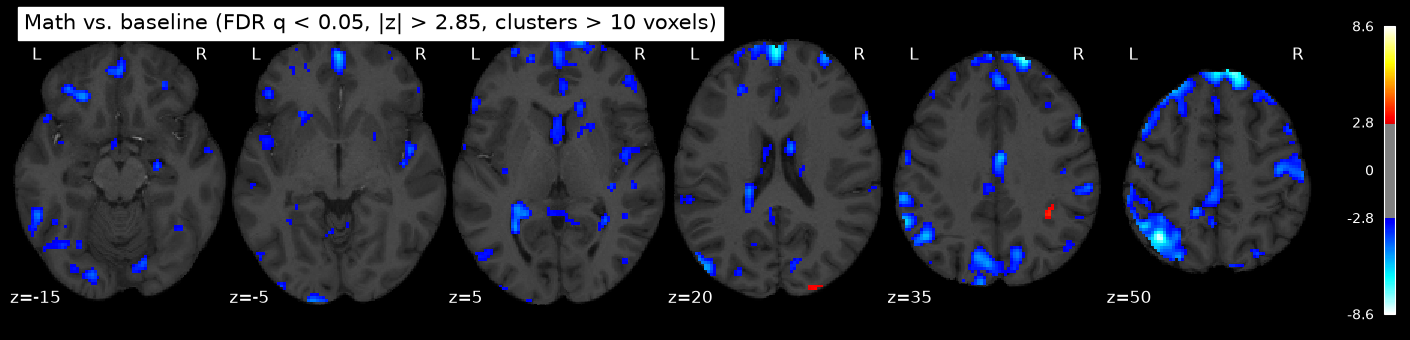

In [44]:
# Statistical maps of each task regressor (each condition vs. implicit baseline)

cluster_size = 10    # minimum cluster size (voxels)
fdr_rate = 0.05      # FDR-corrected q

for cond in ["story", "math"]:
    z_map = fmri_glm.compute_contrast(cond, output_type="z_score")
    clean_map, threshold = threshold_stats_img(z_map, alpha=fdr_rate,
                                               height_control="fdr", cluster_threshold=cluster_size)
    display = plot_stat_map(clean_map, bg_img=anat_mni_path, threshold=threshold,
                            display_mode="z", cut_coords=[-15, -5, 5, 20, 35, 50], black_bg=True,
                            title=f"{cond.capitalize()} vs. baseline (FDR q < {fdr_rate}, "
                                 f"|z| > {threshold:.2f}, clusters > {cluster_size} voxels)")
    display.savefig(op.join(fig_dir, f"3c_{cond}_map.png"), dpi=300)
    plt.show()

**Result:** Both maps are dominated by negative effects and overlap strongly, although story and math are very different tasks. Since the run contains almost no rest, the baseline is poorly estimated and these maps cannot be interpreted as task activity. The story − math contrast (3.d) is used instead.

### 3.d. Contrast vector

The story − math contrast compares the two conditions directly (+1 story, −1 math, 0 for all other regressors), so the poorly estimated baseline cancels out. The same thresholds as in 3.c are used.

In [45]:
# Story vs. math contrast

# Contrast vector: +1 story, -1 math, 0 for all nuisance regressors
contrast_vector = np.zeros(design_matrix.shape[1])
contrast_vector[design_matrix.columns.get_loc("story")] = 1
contrast_vector[design_matrix.columns.get_loc("math")] = -1
print(pd.Series(contrast_vector, index=design_matrix.columns).astype(int).to_string())

math                 -1
story                 1
rot_x                 0
rot_y                 0
rot_z                 0
trans_x               0
trans_y               0
trans_z               0
motion_outlier_025    0
motion_outlier_026    0
motion_outlier_045    0
drift_1               0
drift_2               0
drift_3               0
constant              0


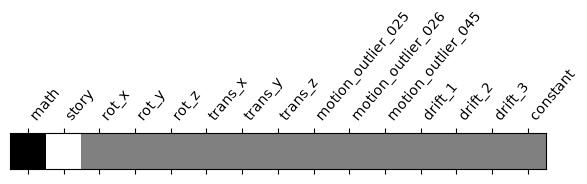

In [46]:
# Contrast vector figure (to include in the report)
ax = plot_contrast_matrix(contrast_vector, design_matrix=design_matrix)
ax.get_figure().savefig(op.join(fig_dir, "3d_contrast_vector.png"), dpi=300, bbox_inches="tight")
plt.show()

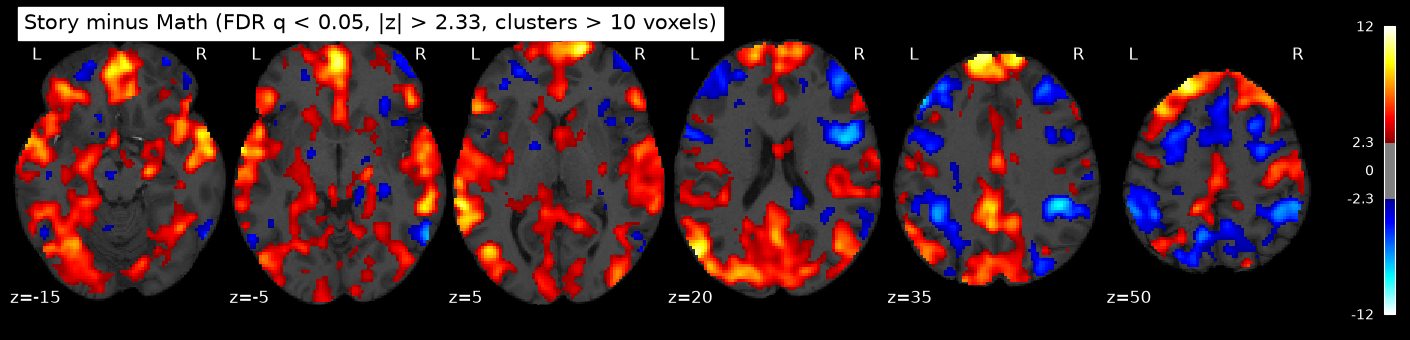

In [47]:
# z-score map, FDR correction + cluster threshold (same parameters as 3c)
z_map = fmri_glm.compute_contrast(contrast_vector, output_type='z_score')
clean_map, threshold = threshold_stats_img(z_map, alpha=fdr_rate, height_control='fdr',
                                           cluster_threshold=cluster_size)

display = plot_stat_map(clean_map, bg_img=anat_mni_path, threshold=threshold,
                        display_mode='z', cut_coords=[-15, -5, 5, 20, 35, 50], black_bg=True,
                        title=f'Story minus Math (FDR q < {fdr_rate}, |z| > {threshold:.2f}, '
                              f'clusters > {cluster_size} voxels)')
display.savefig(op.join(fig_dir, '3d_story_minus_math.png'), dpi=300)
plt.show()

**Result:** Unlike the single-condition maps, the contrast shows a clear dissociation between story > math (red) and math > story (blue) effects, in distinct regions. Their interpretation is discussed in the report.

### 3.e. Comparison with functional networks

To interpret the contrast of 3.d., the map is compared voxel-wise with the Yeo et al. (2011) 7-network atlas. As the atlas is at 1 mm resolution and the contrast map at 2 mm, the atlas is resampled to the grid of the contrast map with nearest-neighbour interpolation, which keeps the integer network labels. For each network, we then compute the percentage of its voxels showing a significant effect in each direction.

                   story > math (%)  math > story (%)
network                                              
Visual                         51.2               2.0
Somatomotor                    45.9               1.9
Dorsal attention               12.8              29.8
Ventral attention              19.8              14.9
Limbic                         29.2               0.9
Frontoparietal                  9.5              29.2
Default mode                   57.6               2.5


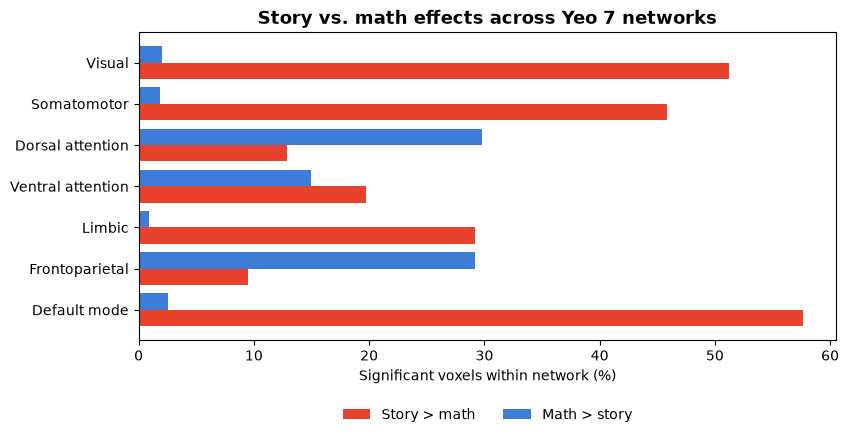

In [51]:
# Overlap of the story-minus-math contrast with the Yeo 7-network atlas

# Yeo et al. (2011) 7-network atlas, liberal mask
# (file copied from the FreeSurfer distribution available on Neurodesk)
yeo_path = op.join("atlases", "Yeo2011_7Networks_MNI152_FreeSurferConformed1mm_LiberalMask.nii.gz")
yeo_img = nli.load_img(yeo_path)
if yeo_img.ndim == 4:
    yeo_img = nli.index_img(yeo_img, 0)

# Resample the atlas to the grid of the contrast map (2 mm) (atlas in 1mm)
# nearest neighbour keeps integer network labels (1-7, 0 = outside cortex) 
contrast_map = clean_map 
yeo_res = nli.resample_to_img(yeo_img, contrast_map, interpolation="nearest")
labels = np.rint(yeo_res.get_fdata()).astype(int)
z = contrast_map.get_fdata()

# For each network: % of its voxels significant in each direction
# z > 0: story > math ; z < 0: math > story
networks = ["Visual", "Somatomotor", "Dorsal attention", "Ventral attention",
            "Limbic", "Frontoparietal", "Default mode"] # = Yeo label order 1-7

rows = []
for k, name in enumerate(networks, start=1):
    in_net = labels == k
    rows.append({"network": name,
                 "story > math (%)": 100 * np.mean(z[in_net] > 0),
                 "math > story (%)": 100 * np.mean(z[in_net] < 0)})
overlap = pd.DataFrame(rows).set_index("network")
print(overlap.round(1))

# Figure: share of each network significant in each direction
fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(networks))
ax.barh(y + 0.2, overlap["story > math (%)"], height=0.4, color="#E8412C", label="Story > math")
ax.barh(y - 0.2, overlap["math > story (%)"], height=0.4, color="#3D7DD8", label="Math > story")
ax.set_yticks(y)
ax.set_yticklabels(networks)
ax.invert_yaxis()
ax.set_xlabel("Significant voxels within network (%)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False)
ax.set_title("Story vs. math effects across Yeo 7 networks", fontsize=13, fontweight="bold")
fig.savefig(op.join(fig_dir, "3e_yeo_networks.png"), dpi=300, bbox_inches="tight")
plt.show()

**Result:** Story > math and math > story effects fall into different networks. The percentages depend on the FDR threshold and only cover the cortex. Their interpretation is discussed in the report.

## 4. PCA

### 4.0. Preprocess

In [54]:
from sklearn.decomposition import PCA
from nilearn.plotting import plot_stat_map
from IPython.display import display as ipy_display

# Load the smoothed fMRI
pca_img = nib.load(fmri_preproc_path)
data = pca_img.get_fdata(dtype=np.float32)
assert data.ndim == 4, "Expected a 4D fMRI image."

# Get spatial information
pca_affine = pca_img.affine
vol_shape = data.shape[:3]

# Brain mask
# The fMRI is already on the MNI152 2mm grid, so we use the MNI152 2mm brain mask
pca_mask_path = op.expandvars(op.join("$FSLDIR", "data", "standard", "MNI152_T1_2mm_brain_mask.nii.gz"))
pca_mask_img = nli.resample_to_img(pca_mask_path, nli.index_img(pca_img, 0), interpolation="nearest")
pca_mask = pca_mask_img.get_fdata() > 0.5

# Remove voxels with no signal or no temporal variance
pca_mask &= (data.mean(axis=-1) > 0) & (data.std(axis=-1) > 0)

assert pca_mask.shape == vol_shape, "Mask shape does not match fMRI."

print("fMRI shape:", data.shape)
print("Number of timepoints:", data.shape[-1])
print("Number of brain voxels:", pca_mask.sum())

fMRI shape: (91, 109, 91, 316)
Number of timepoints: 316
Number of brain voxels: 228483


### 4.1. Apply PCA
One timepoint = one sample.

We fit at least 10 components.

In [55]:
# Prepare the data
X_pca = data[pca_mask, :].T

# Subtract each voxel's temporal mean
X_pca = X_pca - X_pca.mean(axis=0, keepdims=True)

# Fit PCA
n_fit = min(20, X_pca.shape[0] - 1, X_pca.shape[1])
assert n_fit >= 10, "At least 10 components are needed"

pca_assign = PCA(
    n_components=n_fit,
    svd_solver="randomized",
    random_state=0
)

score_assign = pca_assign.fit_transform(X_pca)
loading_assign = pca_assign.components_

# The sign of each PCA is arbitrary
# We make the strongest voxel of each loading positive and flip the matching score too
peak_idx = np.abs(loading_assign).argmax(axis=1)
pc_signs = np.sign(loading_assign[np.arange(n_fit), peak_idx])
loading_assign *= pc_signs[:, None]
score_assign *= pc_signs[None, :]

print("PCA input:", X_pca.shape)
print("Temporal scores:", score_assign.shape)
print("Spatial loadings:", loading_assign.shape)

PCA input: (316, 228483)
Temporal scores: (316, 20)
Spatial loadings: (20, 228483)


### 4.2. Explain and justify component selection; axial maps

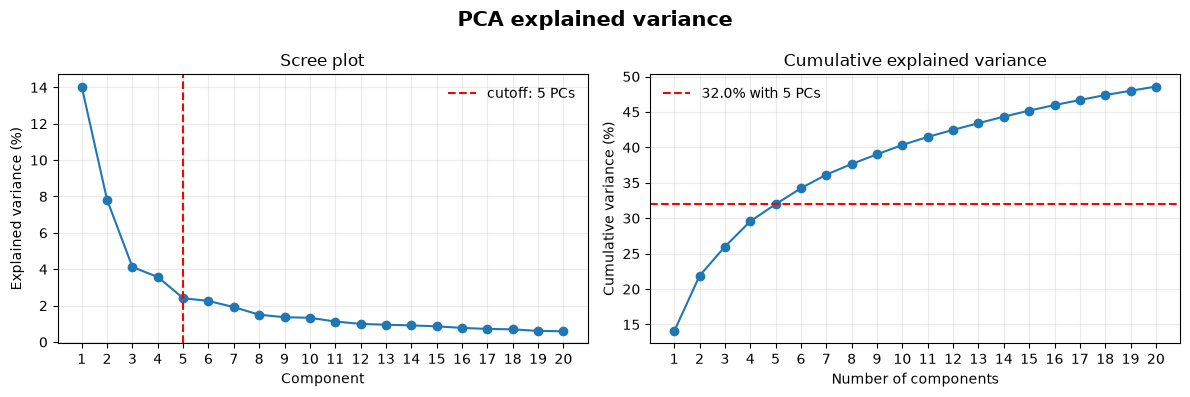

,PC,Explained variance (%),Cumulative variance (%)
0,1,14.04,14.040000
1,2,7.82,21.870001
2,3,4.12,25.990000
3,4,3.58,29.559999
4,5,2.41,31.980000
5,6,2.26,34.230000
6,7,1.92,36.150002
7,8,1.50,37.650002
8,9,1.36,39.009998
9,10,1.33,40.349998


In [56]:
variance_percent = pca_assign.explained_variance_ratio_ * 100
cumulative_percent = np.cumsum(variance_percent)
component_numbers = np.arange(1, n_fit + 1)

n_selected = 5               # elbow of the scree plot (justified below)
assert 1 <= n_selected <= n_fit

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(component_numbers, variance_percent, 'o-')
axs[0].axvline(n_selected, color="r", ls="--", label=f"cutoff: {n_selected} PCs")
axs[0].set(xlabel='Component', ylabel='Explained variance (%)', title='Scree plot')
axs[1].plot(component_numbers, cumulative_percent, 'o-')
axs[1].axhline(cumulative_percent[n_selected - 1], color="r", ls="--",
               label=f"{cumulative_percent[n_selected - 1]:.1f}% with {n_selected} PCs")
axs[1].set(xlabel='Number of components', ylabel='Cumulative variance (%)', 
           title='Cumulative explained variance')
for ax in axs:
    ax.grid(alpha=.25)
    ax.set_xticks(component_numbers)
    ax.legend(frameon=False)

fig.suptitle("PCA explained variance", fontsize=15, fontweight="bold")
fig.tight_layout()
fig.savefig(op.join(fig_dir, "4b_pca_variance.png"), dpi=300, bbox_inches="tight")
plt.show()

summary_variance = pd.DataFrame({
    'PC': component_numbers, 
    'Explained variance (%)': np.round(variance_percent, 2),
    'Cumulative variance (%)': np.round(cumulative_percent, 2),
})
ipy_display(summary_variance)

We select the number of components based on the explained variance distribution and the elbow criterion.

Looking at the scree plot, we can see that the elbow of the curve or the cutoff is around n=5, where n is the number of components selected.
Now looking at the explained variance, we can see that the first component explains 14.04% of the total variance, followed by 7.82%, 4.12%, 3.58% and 2.41%, respectively for components 2, 3, 4 and 5.
Together these five components account for approximately 31.98% of the total variance.

After PC5 the curve flattens: each additional component adds little variance and is harder to tell apart from noise.

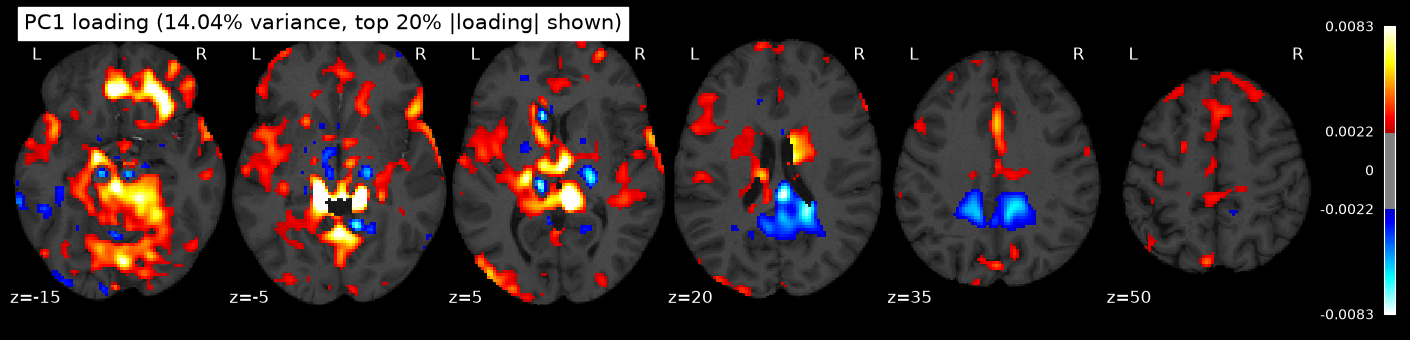

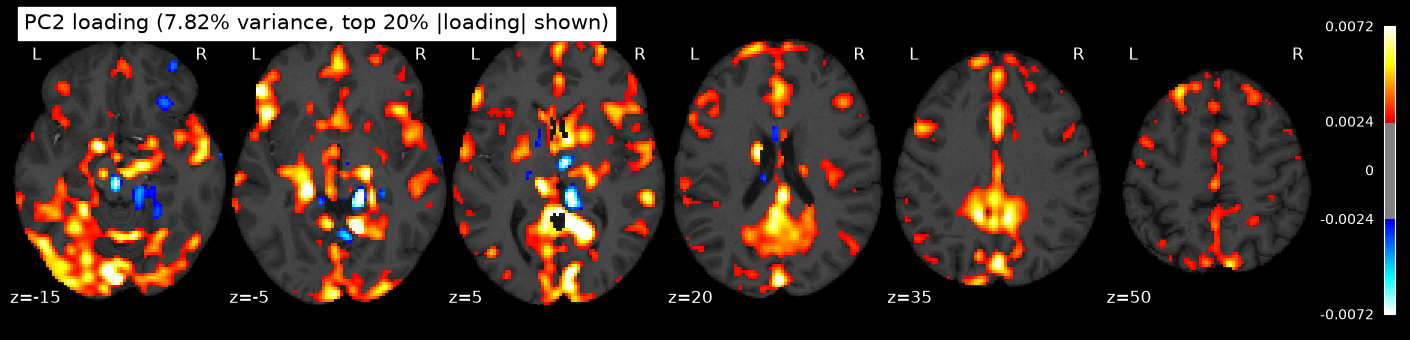

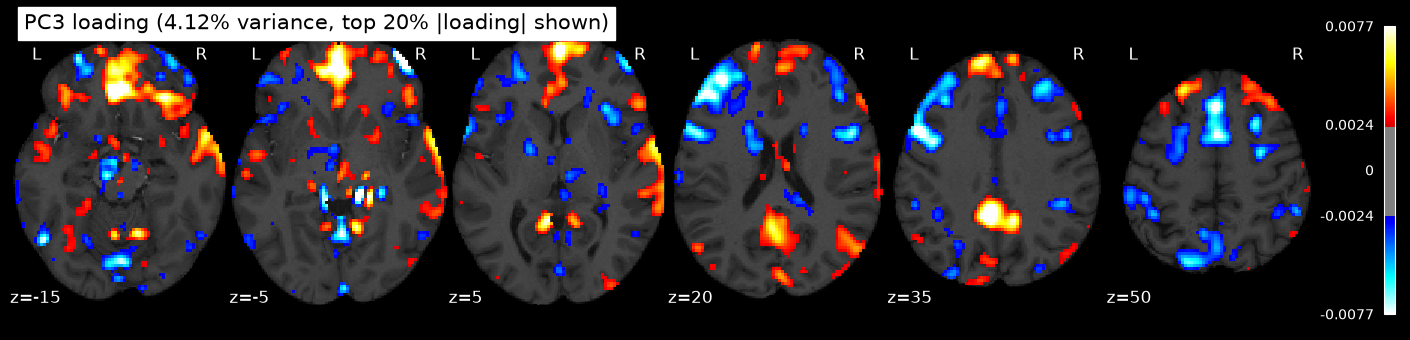

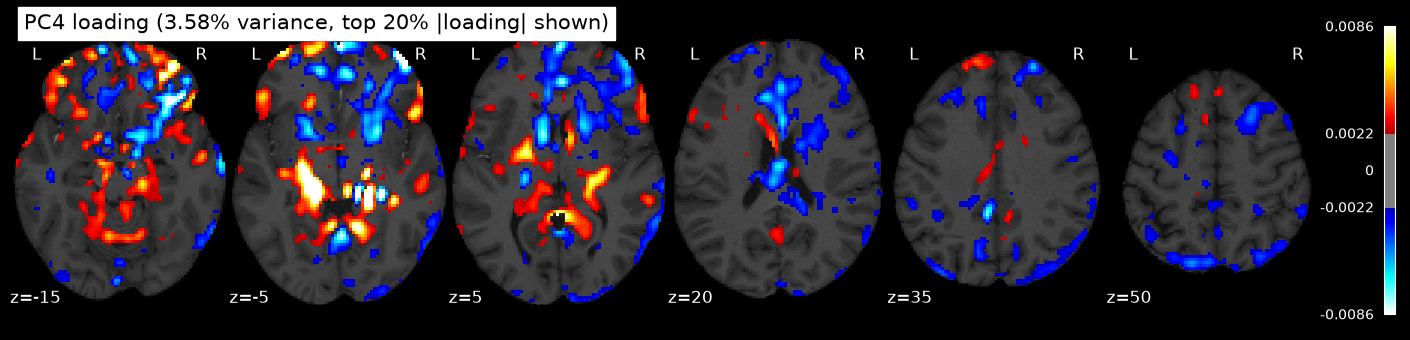

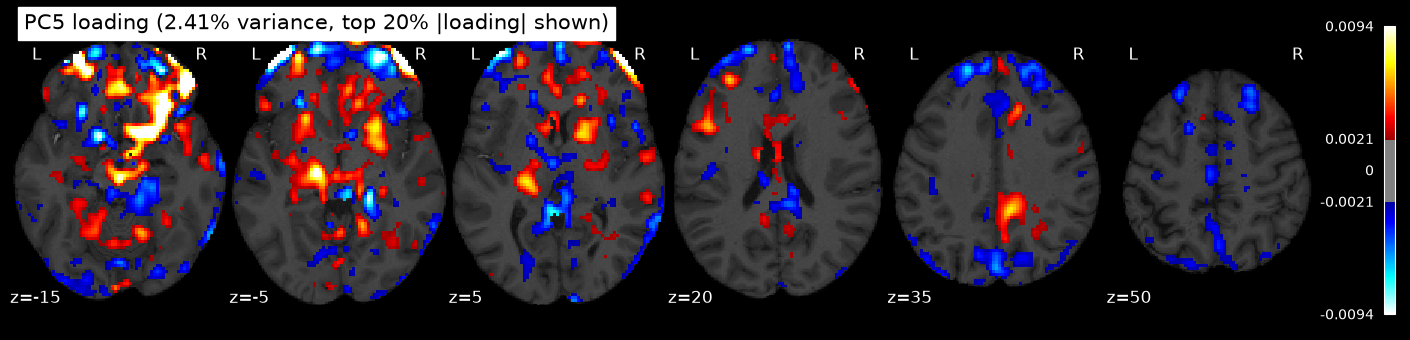

In [57]:
# Same axial levels as the GLM maps
PCA_CUTS = [-15, -5, 5, 20, 35, 50]

pca_loading_volumes, pca_loading_imgs = [], []
for k in range(n_selected):
    loading_vol = np.zeros(vol_shape, dtype=np.float32)
    loading_vol[pca_mask] = loading_assign[k]
    loading_img = nib.Nifti1Image(loading_vol, pca_affine)
    pca_loading_volumes.append(loading_vol)
    pca_loading_imgs.append(loading_img)

    abs_load = np.abs(loading_assign[k])
    disp = plot_stat_map(
        loading_img,
        bg_img=anat_mni_path,                             # MNI T1 from Part 1 (same as 3c, 3d)
        display_mode="z",                                 # axial view only
        cut_coords=PCA_CUTS,
        cmap="cold_hot",
        symmetric_cbar=True,
        colorbar=True,
        vmax=float(np.percentile(abs_load, 99.5)),        # robust to a few extreme voxels
        threshold=float(np.percentile(abs_load, 80)),     # show the 20% strongest loadings
        black_bg=True,
        draw_cross=False,
        title=f"PC{k + 1} loading ({variance_percent[k]:.2f}% variance, top 20% |loading| shown)",
    )
    disp.savefig(op.join(fig_dir, f"4b_pc{k + 1}_loading.png"), dpi=300)
    plt.show()


### 4.3. Correlate the first 10 PCA scores with Part 1 GLM regressors


,math,story,rot_x,rot_y,rot_z,trans_x,trans_y,trans_z,motion_outlier_025,motion_outlier_026,motion_outlier_045,drift_1,drift_2,drift_3
PC1,-0.218,0.150,-0.578,-0.225,-0.055,-0.240,0.211,0.026,0.058,0.078,0.062,0.789,0.049,-0.026
PC2,-0.379,0.337,0.423,0.195,-0.352,0.158,-0.107,0.090,-0.011,-0.024,0.002,-0.390,0.323,0.085
PC3,-0.697,0.701,0.019,-0.495,0.065,-0.506,-0.327,0.137,0.003,-0.014,-0.028,0.197,-0.108,-0.153
PC4,-0.174,0.184,-0.094,0.207,0.068,0.242,0.430,-0.424,0.042,0.081,0.037,0.092,0.384,0.290
PC5,-0.037,0.024,-0.149,-0.120,0.144,0.002,0.173,-0.242,0.078,-0.022,0.061,0.198,0.257,0.146
PC6,0.292,-0.316,-0.082,-0.241,0.098,-0.265,-0.118,0.132,0.019,-0.063,-0.006,0.152,-0.256,0.173
PC7,0.131,-0.140,-0.121,-0.170,0.004,-0.205,0.138,0.057,-0.023,0.034,-0.040,0.171,0.124,0.117
PC8,0.001,-0.004,-0.008,0.065,-0.108,0.168,0.118,-0.066,-0.003,0.014,0.020,-0.069,0.097,-0.006
PC9,0.048,-0.076,-0.092,-0.195,0.092,-0.202,-0.035,-0.014,-0.062,-0.035,-0.036,0.109,-0.085,0.097
PC10,0.108,-0.016,-0.130,-0.058,-0.090,-0.029,0.148,-0.160,-0.085,-0.086,-0.034,-0.051,-0.122,-0.254


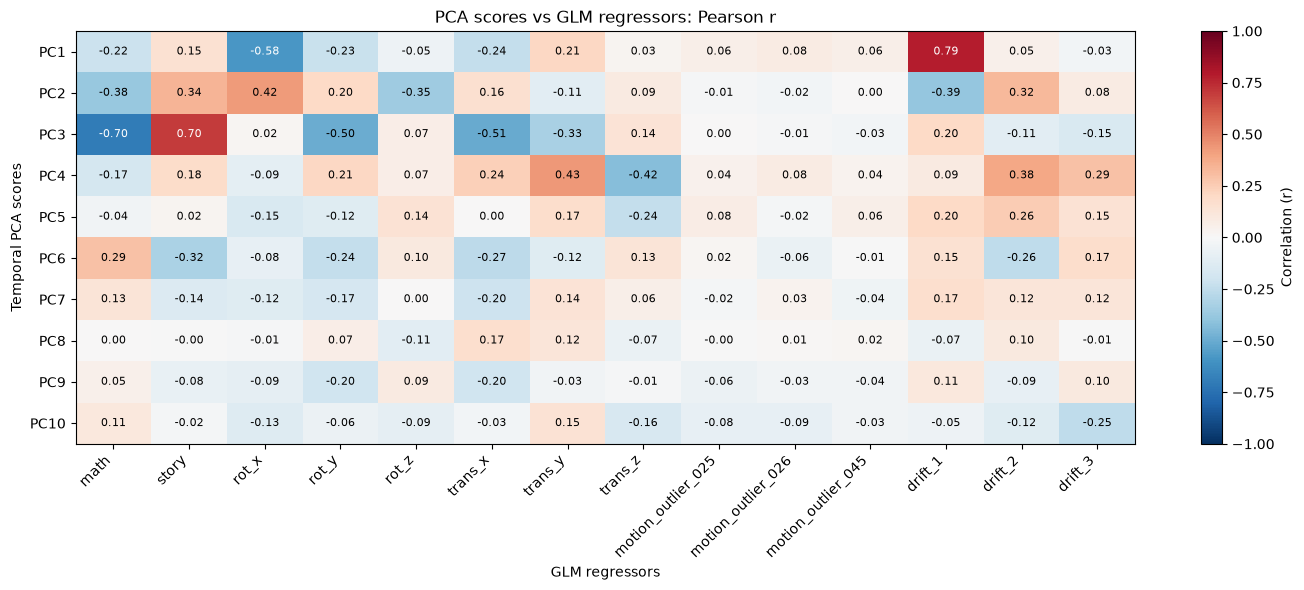

,Strongest GLM regressor,Pearson r
PC1,drift_1,0.789
PC2,rot_x,0.423
PC3,story,0.701
PC4,trans_y,0.430
PC5,drift_2,0.257
PC6,story,-0.316
PC7,trans_x,-0.205
PC8,trans_x,0.168
PC9,trans_x,-0.202
PC10,drift_3,-0.254


In [59]:
glm = pd.DataFrame(design_matrix).copy()

assert len(glm) == score_assign.shape[0], \
    "GLM and PCA must have the same number of timepoints"

# Keep numeric regressors only
glm = glm.select_dtypes(include=[np.number])

# Remove constant columns
glm = glm.loc[:, glm.std(axis=0) > 1e-10]

# First 10 temporal PCA scores
scores10 = score_assign[:, :10]

scores_df = pd.DataFrame(
    scores10,
    columns=[f"PC{i+1}" for i in range(10)]
)

# Compute Pearson correlation matrix
corr = np.corrcoef(
    scores_df.to_numpy().T,
    glm.to_numpy().T
)

# Extract correlations between PCs and GLM
corr_df = pd.DataFrame(
    corr[:10, 10:],
    index=scores_df.columns,
    columns=glm.columns
)

ipy_display(corr_df.round(3))


# Heatmap
fig, ax = plt.subplots(figsize=(max(8, .8 * corr_df.shape[1] + 3), 6))
im = ax.imshow(corr_df.to_numpy(), aspect='auto', vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(np.arange(corr_df.shape[1]), corr_df.columns, rotation=45, ha='right')
ax.set_yticks(np.arange(10), corr_df.index)
ax.set_xlabel('GLM regressors')
ax.set_ylabel('Temporal PCA scores')
ax.set_title('PCA scores vs GLM regressors: Pearson r')
fig.colorbar(im, ax=ax, label='Correlation (r)')
for i in range(corr_df.shape[0]):
    for j in range(corr_df.shape[1]):
        val = corr_df.iat[i, j]
        if corr_df.shape[1] <= 18:
            ax.text(j, i, f'{val:.2f}', ha='center', va='center',
                    fontsize=8, color='white' if abs(val) > .55 else 'black')
plt.tight_layout()
plt.show()

# Identifying strongest GLM association by absolute r for each component
max_cols = corr_df.abs().idxmax(axis=1)
max_vals = [corr_df.loc[row, col] for row, col in zip(corr_df.index, max_cols)]
strongest = pd.DataFrame({'Strongest GLM regressor': max_cols,
                          'Pearson r': np.round(max_vals, 3)})

ipy_display(strongest)

We notice that the components explaining the most variance are not necessarily those most strongly associated with the experimental tasks.
- PC1 (`14.04%` of variance) correlates with drift_1 (`r = 0.79`) and rot_x (`r = −0.58`). Its broad map, centred on the ventricles and brain edges, points to slow drift and head motion.
- PC2 (`7.82%` of variance) has a map that is positive almost everywhere, like a global signal. It correlates moderately with the task (`|r| ≈ 0.35`) and to a similar degree with motion and drift.
- PC3 (`4.12%` of variance) shows the strongest correlations with the task: it correlates with story (r = `0.70`) and anti-correlates with math (r = `−0.70`). It also correlates with motion (trans_x r = `−0.51`, rot_y r = `−0.50`), so it may mix task-related and motion-related variance.
- PC4 (`3.58%` of variance) and PC5 (`2.41%` of variance) correlate mainly with translations and drifts. Their maps sit along tissue boundaries and the edges of the brain, which points to motion and edge artefacts.
- PC6 to PC10 and the spike regressors show only weak correlations (`|r| ≤ 0.32`) with the GLM regressors.